<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 4: Human Rights approach to data y privacidad <h2><center>


# Human Rights approach to data y privacidad

>Contexto

En estos talleres, estamos trabajando con datos que pueden influir en vidas de personas. Esto implica una responsabilidad ética especial, las personas o grupos de personas detrás pueden verse impactadas tanto de forma positiva como negativa con las decisiones basadas en datos que tomemos. Antes de hacer cualquier análisis, debes preguntarte cómo tratarías esos datos si fueras quien los recolecta, y cómo podrías compartirlos si resguardar la identidad de los involucrados fuese prioridad.

>Objetivos

El objetivo de este taller es diseñar un marco de recolección de datos basado en derechos humanos sobre los problemas que han estado tratando, así como identificar si cumplen o no con el marco regulatorio chileno, aplicar DataSynthesizer para generar una versión sintética del dataset, generar visualizaciones y proponer mejoras al dataset desde la perspectiva del activismo de datos.

> # instrucciones generales

Esta es la parte IV del proyecto, consideren utilizar sus resultados anteriores y reciclar el código de los talleres previos. El taller puede aplicarse sobre cualquiera de los tres datasets del proyecto; trabajen con el mismo dataset que eligieron en los talleres anteriores y respondan cada pregunta en función de ese contexto.

Si trabajan con CIRI, notarán que sus datos son indicadores agregados por país y año, por lo que no contienen información personal que deba protegerse. Aun así, la idea es que aprendan a utilizar las herramientas de privacidad diferencial y generación de datos sintéticos, ya que el procedimiento es el mismo independiente del dataset, y que reflexionen sobre qué ocurriría si estos datos tuvieran un mayor nivel de detalle, por ejemplo, registros individuales de víctimas, como se plantea en la pregunta 6.

## `Temas formales`

Modalidad: Grupos de 3 personas.

Fecha de entrega: 20 de noviembre.

Formato de entrega: El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

Formalidades de las respuestas:
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "sí" o "no", consideren argumentar sus respuestas y justificar con bibliografía si lo estiman necesario.

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes :D.



In [19]:
# importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



### _`Importantes: A lo largo del notebook habrán preguntas guías para los análisis de resultados, operación de código y otros, se espera que las respondan o hagan alusión a ellas en sus respuestas `_

<br><br>
**`Pregunta (1`) Describa el objetivo y las variables del dataset desde una perspectiva distinta**.

¿A simple vista, consideras que alguna de estas variables podría ser mal utilizada, perjudicando a alguna comunidad?

¿Por qué crees que se consideran esas variables y no otras para el objetivo del dataset?

<br><br>


**Respuesta (1)**

Para los hogares encuestados, responder CASEN implica que una persona informante, mayor de 18 años, entregue en representación de todo el hogar información sobre la vivienda, el trabajo, la salud, la previsión y la educación de sus integrantes, además de su identidad (Ministerio de Desarrollo Social y Familia [MDSF], 2026a, p. 56). La entrevista es voluntaria y su mediana de duración es de 56 minutos (MDSF, 2026b). A cambio, el beneficio es indirecto: al hogar que duda se le explica que la encuesta es un insumo fundamental para el diseño y la evaluación de políticas públicas, bajo criterios de confidencialidad, reserva y anonimato (MDSF, 2026a, p. 57). La relación es asimétrica, porque el Ministerio define el contenido del cuestionario. Según el documento metodológico, las necesidades se identificaron dentro de la División Observatorio Social y se consultaron con contrapartes institucionales, como ministerios y servicios públicos, en los Talleres Casen (MDSF, 2026a, pp. 21-24), sin que se describa una consulta a los hogares encuestados.

Varias variables del conjunto de datos presentan riesgos de mal uso si las aprovechan actores con incentivos discriminatorios. Las de identidad de género y orientación sexual (`trans` y `os1`) podrían servir para perfilar, excluir laboralmente o estigmatizar a la comunidad LGBTQ+. Las de pertenencia a pueblos indígenas y nacionalidad (`r3` y `r1a`) podrían usarse para reforzar discursos xenófobos o para excluir a pueblos originarios y población migrante de servicios privados, como el arriendo o el crédito. Las de dificultad funcional (`h7e` y `h7f`), junto con `pobreza_multi`, podrían servir para negar crédito u ofrecer condiciones abusivas a hogares vulnerables. El riesgo aumenta al cruzar estas variables con cuasi-identificadores como `area` o `edad`: solo 54 de los 212.471 registros responden "Sí" en `trans` y, al cruzarlos con `area` y cinco tramos de edad (0-17, 18-29, 30-44, 45-59 y 60 años o más), tres de las seis celdas con casos tienen menos de cinco personas y una tiene una sola. Celdas así facilitan la reidentificación.

El dataset de trabajo tiene 42 variables, mientras que la base pública de Casen 2024 contiene 877 (MDSF, 2026c, p. 6). Incluye variables de vivienda y entorno, salud, educación, trabajo y seguridad social, identidades y la variable `pobreza_multi`, pero no incluye región, comuna, ingresos ni pobreza por ingresos. La base pública excluye la información que identifique explícitamente a las personas encuestadas o su ubicación, para cumplir protocolos de anonimización, y la información de provincia y comuna se publica en una base aparte (MDSF, 2026c, pp. 5-6). El criterio para elegir estas 42 variables no está documentado en el material revisado, pero es plausible que se priorizara el objetivo de medir la pobreza multidimensional y que se dejaran fuera la comuna y el ingreso por ser cuasi-identificadores potentes.

**Referencias**

Ministerio de Desarrollo Social y Familia. (2026a). *Documento metodológico del proceso estadístico Casen 2024*. División Observatorio Social, Subsecretaría de Evaluación Social. https://observatorio.ministeriodesarrollosocial.gob.cl/storage/docs/casen/2024/Informe_metodologico_casen_2024.pdf

Ministerio de Desarrollo Social y Familia. (2026b). *Ficha técnica Casen 2024*. División Observatorio Social. https://observatorio.ministeriodesarrollosocial.gob.cl/storage/docs/casen/2024/Ficha_tecnica_Casen_2024.pdf

Ministerio de Desarrollo Social y Familia. (2026c). *Nota uso bases de datos Casen 2024*. División Observatorio Social. https://observatorio.ministeriodesarrollosocial.gob.cl/storage/docs/casen/2024/Nota_uso_bases_de_datos_Casen_2024.pdf


### `2: Exploración de datos y limpieza.`

Basta con que lo hayan realizado en los talleres anteriores, solo consideren usar el dataset limpio para lo que viene.

Se reutiliza la carga y limpieza de los Talleres 1 a 3, con el dataset CASEN 2024 preprocesado entregado por el curso. Lo que sigue deja `casen` cargado, con los tipos corregidos y los nulos revisados, para el resto del taller.

In [20]:
# Cargamos el dataset
file_id = "1DQsXd6hThmoROcqSqVlBPEO-jb0joKj9"
url = f"https://drive.google.com/uc?export=download&id={file_id}"
casen = pd.read_csv(url)
print(casen.shape)

(212471, 42)


En la siguiente celda convertimos a categóricas las columnas que vienen en formato numérico, pero representan códigos de respuesta u opciones cualitativas. Mantener esos códigos como variables numéricas permitiría que el modelo estableciera cortes según su valor, introduciendo un orden que puede no corresponder al significado de las categorías. La conversión permite identificarlas como categóricas y aplicarles después la codificación One-Hot del preprocesamiento.

In [21]:
# Listado de variables que son numéricas pero corresponden a categorías
vars_to_cat = ['p2', 'p3', 'p4', 'p9', 'h7e', 'h7f', 'r14', 'r17a', 'r17b', 'r17c', 'v3', 'v5', 'v23']
for col in vars_to_cat:
    if col in casen.columns:
        casen[col] = casen[col].astype('category')
print(casen[vars_to_cat].dtypes)

p2      category
p3      category
p4      category
p9      category
h7e     category
h7f     category
r14     category
r17a    category
r17b    category
r17c    category
v3      category
v5      category
v23     category
dtype: object


Cuantificamos los valores nulos por columna con `casen.isnull().sum()`. La salida guardada muestra cero nulos en todas las columnas, por lo que no fue necesario rellenar valores ni eliminar registros por este motivo. Esta comprobación se refiere a los valores que pandas reconoce como nulos.

In [22]:
# Verificamos la cantidad de nulos por columna
print(casen.isnull().sum())

area             0
p1               0
p2               0
p3               0
p4               0
p9               0
tot_per_h        0
edad             0
sexo             0
ind_hacina       0
e1               0
e9depen          0
o1               0
o19              0
o31              0
s13              0
h7e              0
h7f              0
r1a              0
r3               0
r14              0
r17a             0
r17b             0
r17c             0
v1               0
v2               0
v3               0
v4               0
v5               0
v6               0
v13              0
v20              0
v22              0
v23              0
v24              0
v24b             0
v27a             0
v27b             0
v29b             0
os1              0
trans            0
pobreza_multi    0
dtype: int64


### `3: Análisis de principios.`

**`Pregunta (3)` Identifique si el dataset seleccionado cumple con los principios de Human Rights approach to data. Si cumple, explique por qué cumple. Si no cumple, proponga un nuevo marco de recolección o tratamiento que sí cumpla.**

Recuerda apoyarte en bibliografía externa, puedes sugerir marcos y métodos de tratamiento de datos utilizados en casos similares. Argumenta sólidamente tu elección.



**Respuesta (3)**

| Principio | Qué exige | ¿Cumple? | Fundamento |
|---|---|---|---|
| Participación | Los grupos afectados participan activa y voluntariamente en planificar, recolectar y analizar | No | La identificación de necesidades del cuestionario se hizo dentro del Ministerio y con contrapartes institucionales, como ministerios, servicios públicos y un panel de personas expertas (MDSF, 2026a, pp. 21-24; MDSF, 2026b). Las personas afectadas participaron como informantes y, en un submódulo de pensiones, en grupos focales (MDSF, 2026a, p. 36), pero el documento metodológico no describe participación de pueblos indígenas, de la población LGBTQ+ ni de organizaciones de hogares en el diseño o el análisis. Las organizaciones locales y vecinales aparecen solo en una carta destinada a mejorar las tasas de respuesta (MDSF, 2026a, p. 55). |
| Desagregación | Los datos se desagregan por características clave del derecho internacional de DD. HH. | A medias | El documento metodológico plantea evaluar brechas entre mujeres y hombres, personas mayores, pueblos indígenas y personas nacidas fuera de Chile (MDSF, 2026a, p. 12), y el dataset permite desagregar por `sexo`, `edad`, `area`, `r3`, `r1a` y dificultades funcionales (`h7e`, `h7f`). Pero el dataset de trabajo no incluye región ni comuna, que la base pública publica en un archivo aparte (MDSF, 2026c, p. 5), por lo que no permite observar brechas territoriales. |
| Autoidentificación | Nadie es categorizado sin su consentimiento consciente e informado | A medias | El módulo de orientación sexual e identidad de género (`os1`, `trans`) fue autoaplicado y respondido de forma autónoma por personas de 18 años o más, y ambas variables ofrecen la opción "Prefiere no responder" (MDSF, 2026a, p. 56). El resto del cuestionario, incluidas `r3` y `r1a`, lo responde una persona informante en representación de todos los integrantes del hogar (MDSF, 2026a, p. 56), por lo que esas categorías no siempre las declara la persona aludida. |
| Transparencia | Información clara sobre métodos y diseño, y datos públicos accesibles | Sí | El Observatorio Social publica la base de datos, la ficha técnica, el documento metodológico y una nota de uso de las bases (MDSF, 2026a; 2026b; 2026c). La nota de uso indica que también se publican los libros de códigos, el cuestionario y el manual para la investigación (MDSF, 2026c, p. 5). |
| Privacidad | Protección fuerte. Lo sensible solo se divulga con consentimiento explícito | A medias | La base pública es anonimizada y excluye identificadores directos como nombres, direcciones y teléfonos (MDSF, 2026b), y a los hogares se les informan garantías de confidencialidad, reserva y anonimato (MDSF, 2026a, p. 57). Sin embargo, persisten celdas pequeñas: solo 54 registros responden "Sí" en `trans` y, al cruzarlos con `area` y tramos de edad, tres de seis celdas tienen menos de cinco personas, lo que expone a reidentificación. Además, los tres documentos revisados no describen un consentimiento específico para divulgar las variables sensibles. |
| Rendición de cuentas | Los datos sirven para exigir responsabilidades al Estado | A medias | La publicación de la base permite que cualquier persona u organización la use para fiscalizar al Estado. Pero el Ministerio es el organismo responsable de la encuesta (MDSF, 2026b) y su propósito declarado es servir de insumo para el diseño y la evaluación de políticas públicas (MDSF, 2026a, p. 57); los documentos revisados no describen un mecanismo para que las comunidades usen sus resultados para exigir responsabilidades. |

**Conclusión general.** CASEN cumple solo en parte con el enfoque de derechos humanos para los datos (United Nations Office of the High Commissioner for Human Rights [OHCHR], 2018). Tiene un buen estándar de transparencia, cumple a medias cuatro principios (desagregación, autoidentificación, privacidad y rendición de cuentas) y no cumple el de participación. Esta evaluación se basa en la ficha técnica, el documento metodológico y la nota de uso de Casen 2024, y en el dataset del taller. No se revisaron el cuestionario ni los libros de códigos.

**Propuesta de marco de recolección o tratamiento.** El cambio prioritario es la participación: mesas de codiseño vinculantes con organizaciones sociales, pueblos indígenas y colectivos LGBTQ+ para definir preguntas y categorías antes de cada levantamiento. La propuesta se inscribe en el activismo de datos, que Milan (2017) presenta como una nueva forma de activismo mediático, en la medida en que busca que las comunidades dejen de ser solo objeto de medición y participen en la producción y el uso de los datos que las describen. Para la privacidad, se propone aplicar técnicas formales de anonimización ($k$-anonimato o privacidad diferencial) sobre los cuasi-identificadores y suprimir o agrupar las celdas pequeñas, como los cruces de `trans` con `edad` y `area`, antes de liberar microdatos. Para la desagregación sin comprometer el resguardo individual, se sugiere un acceso diferenciado, con datos sintéticos o agregados de granularidad territorial (región y comuna) para uso abierto y microdatos territoriales detallados solo en entornos seguros de investigación, bajo acuerdos de confidencialidad.

**Referencias**

Milan, S. (2017). Data activism as the new frontier of media activism. En V. Pickard y G. Yang (Eds.), *Media activism in the digital age* (pp. 151-163). Routledge.

Ministerio de Desarrollo Social y Familia. (2026a). *Documento metodológico del proceso estadístico Casen 2024*. División Observatorio Social, Subsecretaría de Evaluación Social. https://observatorio.ministeriodesarrollosocial.gob.cl/storage/docs/casen/2024/Informe_metodologico_casen_2024.pdf

Ministerio de Desarrollo Social y Familia. (2026b). *Ficha técnica Casen 2024*. División Observatorio Social. https://observatorio.ministeriodesarrollosocial.gob.cl/storage/docs/casen/2024/Ficha_tecnica_Casen_2024.pdf

Ministerio de Desarrollo Social y Familia. (2026c). *Nota uso bases de datos Casen 2024*. División Observatorio Social. https://observatorio.ministeriodesarrollosocial.gob.cl/storage/docs/casen/2024/Nota_uso_bases_de_datos_Casen_2024.pdf

United Nations Office of the High Commissioner for Human Rights. (2018). *A human rights-based approach to data: Leaving no one behind in the 2030 agenda for sustainable development*. https://www.ohchr.org/en/documents/tools-and-resources/human-rights-based-approach-data-leaving-no-one-behind-2030-agenda

<br><br>
### `4: Análisis regulatorio.`

**`Pregunta (4)` Proponga un método de recolección de este tipo de datos imaginando que fuese requerido para Chile. El método debe cumplir con el marco regulatorio chileno, considerando las políticas que entraron y entrarán en vigencia.**

Al momento de explicar el método propuesto, recuerda hacer alusión a principios, temas y/o artículos específicos de la regulación vigente o de discusiones académicas en torno a esta.

Para recolectar en Chile datos socioeconómicos, de salud, educación, vivienda e identidad como los de la encuesta CASEN 2024, el método debe combinar el marco legal vigente con los nuevos estándares regulatorios que entrarán en vigor próximamente. Aunque el artículo 20 de la Ley N° 19.628 permite a los organismos públicos tratar datos dentro de sus competencias sin consentimiento obligatorio, en una encuesta voluntaria de hogares se debe privilegiar una autorización libre e informada, alineada con los principios de licitud, lealtad y transparencia de la Ley N° 21.719, cuya entrada en vigencia fue prorrogada hasta 2027, y con el deber de secreto estadístico de los artículos 29 y 30 de la Ley N° 17.374. Antes de comenzar, se debe informar de manera simple qué datos se solicitarán, con qué finalidad pública se usarán y cómo serán resguardados.   

En cuanto al cuidado de la información y la calidad de la recolección, el artículo 2 de la Ley N° 19.628 protege de forma especial los datos sensibles como el estado de salud y el origen racial, lo que en nuestra base abarca variables como os1, trans, r3, r1a, h7e y h7f. Para cumplir con la protección reforzada de la Ley N° 21.719 sobre datos sensibles y menores de edad, el cuestionario debe mantener respuestas confidenciales en materias íntimas, pedir autorización de los responsables legales respecto de menores y evitar que un solo informante declare por todo el hogar cuando eso pueda afectar la veracidad de los datos. Además, siguiendo el artículo 9 de la Ley N° 19.628 y el principio de minimización de la Ley N° 21.719, se deben pedir solo las variables estrictamente necesarias para el análisis, reduciendo la extensión excesiva de la encuesta original.

Finalmente, para garantizar los derechos de acceso y rectificación reconocidos en el artículo 12 de la Ley N° 19.628 y ampliados por la Ley N° 21.719, el sistema debe separar la gestión interna de la publicación. Durante la recolección y revisión de datos se puede usar un código temporal guardado en una tabla separada y de acceso muy restringido para ubicar al hogar si pide corregir algún dato erróneo. Una vez cerrada esa etapa, la tabla de enlace se elimina y la base pública se entrega completamente anonimizada, agrupando cruces poco frecuentes de edad, área e identidad para impedir que alguien sea identificado.

Referencias:

Biblioteca del Congreso Nacional de Chile. (1970). Ley N° 17.374: Fija nuevo texto refundido, coordinado y actualizado del D.F.L. N° 313 de 1960, que aprobara la Ley Orgánica Dirección Estadística y Censos y crea el Instituto Nacional de Estadísticas. https://www.bcn.cl/leychile/navegar?idNorma=28960

Biblioteca del Congreso Nacional de Chile. (1999). Ley N° 19.628: Sobre protección de la vida privada. https://www.bcn.cl/leychile/navegar?idNorma=141599

Biblioteca del Congreso Nacional de Chile. (2024). Ley N° 21.719: Regula la protección y el tratamiento de los datos personales y crea la Agencia de Protección de Datos Personales. https://www.bcn.cl/leychile/navegar?idNorma=1209272

<br><br>
### `5: Privacidad diferencial.`

**`Pregunta (5)` Aplica las técnicas de privacidad diferencial vistas para anonimizar el dataset y comenta los resultados.**

      - Selecciona a lo más 7 variables para aplicar la técnica. Menciónalas y justifica tu elección.
      - Obtenga la descripción del dataset en alguno de los modos, justifique su elección. Guarde dicha descripción en un archivo local
      (en formato JSON)
      - Genere los datos sintéticos usando DataGenerator
      - Aplique ModelInspector para comparar las distribuciones entre los datos originales y los datos sintéticos.

<br><br>

### Usaremos las siguientes variables:

* **`edad`**: Dato demográfico clave y cuasi-identificador para observar cómo se comporta la distribución etaria al sintetizar.


* **`sexo`**: Variable demográfica básica para analizar el resguardo y la distribución por sexo en los datos sintéticos.


* **`area`**: Indica zona urbana o rural y permite ver la distribución territorial general sin exponer comuna ni región.


* **`pobreza_multi`**: Resume la pobreza multidimensional del hogar, central para el fin social de CASEN y sensible al cruzarse con otros datos.


* **`r3`**: Refleja pertenencia a pueblos indígenas, es relevante para evaluar grupos protegidos frente a riesgos de discriminación.


* **`r1a`**: Refleja nacionalidad o condición migratoria, es útil para observar poblaciones con posibles barreras de acceso o estigmatización.


* **`trans`**: Indica identidad de género trans, es una variable sensible con pocos casos que ayuda a evaluar el efecto de la privacidad.

In [23]:
import json
from DataSynthesizer.DataDescriber import DataDescriber
from DataSynthesizer.DataGenerator import DataGenerator
from DataSynthesizer.ModelInspector import ModelInspector

cols = ['edad', 'sexo', 'area', 'pobreza_multi', 'r3', 'r1a', 'trans']
df_7 = casen[cols].copy()

for c in ['sexo', 'area', 'pobreza_multi', 'r3', 'r1a', 'trans']:
    df_7[c] = df_7[c].astype(str)

df_7['edad'] = df_7['edad'].astype(int)

input_csv = 'casen_7.csv'

df_7.to_csv(input_csv, index=False)

fila_dscrp = 'casen_descripcion.json'

Se eligió el modo de atributos independientes (`independent_attribute_mode`) en `DataDescriber` y `DataGenerator` por ser el enfoque más directo, rápido y sencillo de aplicar con privacidad diferencial sobre las siete variables seleccionadas de CASEN 2024. Este modo modela cada variable por separado sin construir relaciones entre columnas, lo que facilita el procesamiento y la comparación inmediata de distribuciones con `ModelInspector`, aunque tiene como limitación que no conserva las correlaciones ni los cruces entre variables del conjunto original.

In [24]:
describer = DataDescriber(category_threshold=20)

describer.describe_dataset_in_independent_attribute_mode(
    dataset_file=input_csv,
    epsilon=0.5, # Usamos el epsilon para el ruido de los datos.
    attribute_to_is_categorical={ # Categorizamos algunas columnas
        'edad': False,
        'sexo': True,
        'area': True,
        'pobreza_multi': True,
        'r3': True,
        'r1a': True,
        'trans': True
    }
)
describer.save_dataset_description_to_file(fila_dscrp)

In [25]:
synthetic_csv = 'casen_sintetico.csv'

generator = DataGenerator()

generator.generate_dataset_in_independent_mode( # Generamos los datos sintéticos
    description_file=fila_dscrp,
    n=len(df_7))

generator.save_synthetic_data(synthetic_csv)

df_syn = pd.read_csv(synthetic_csv)

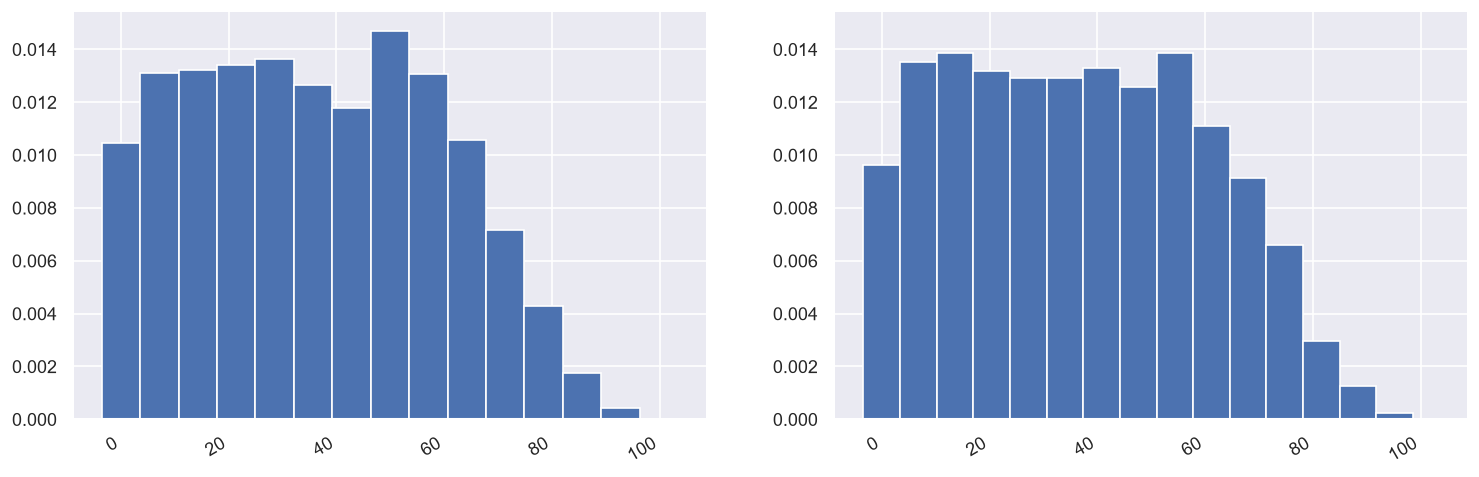

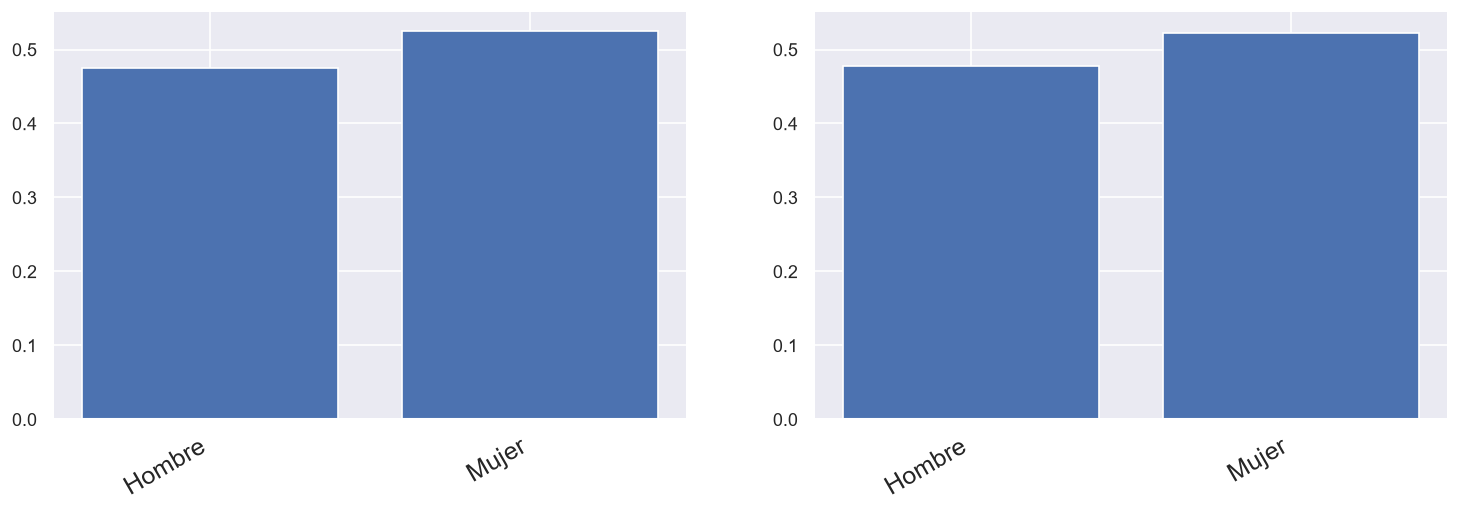

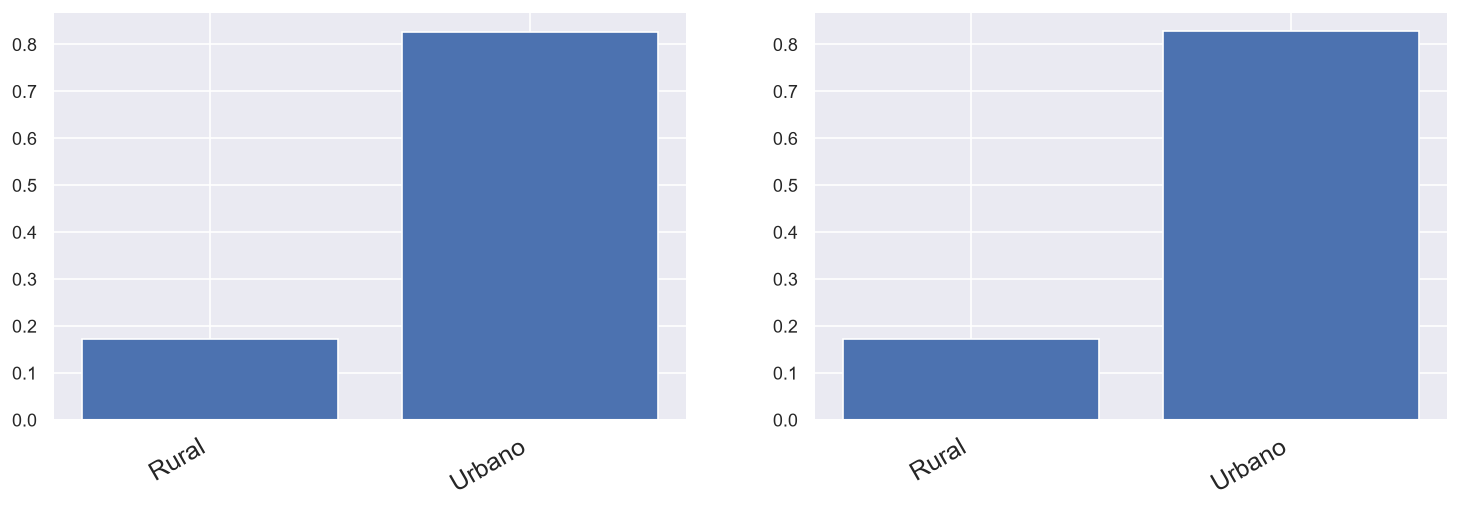

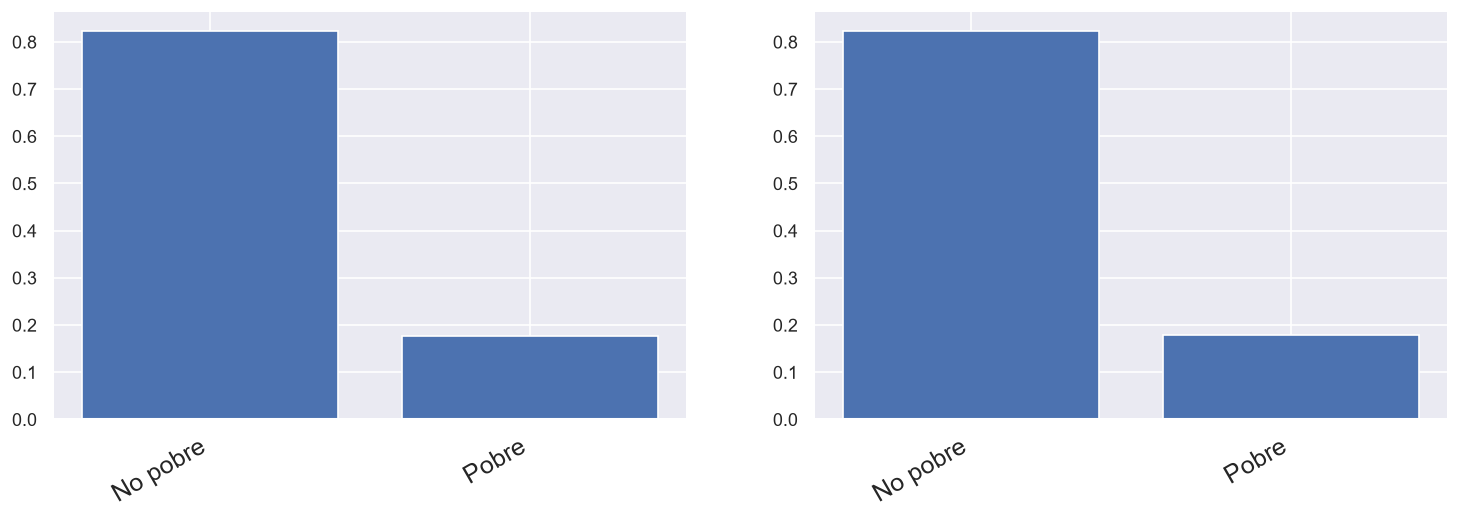

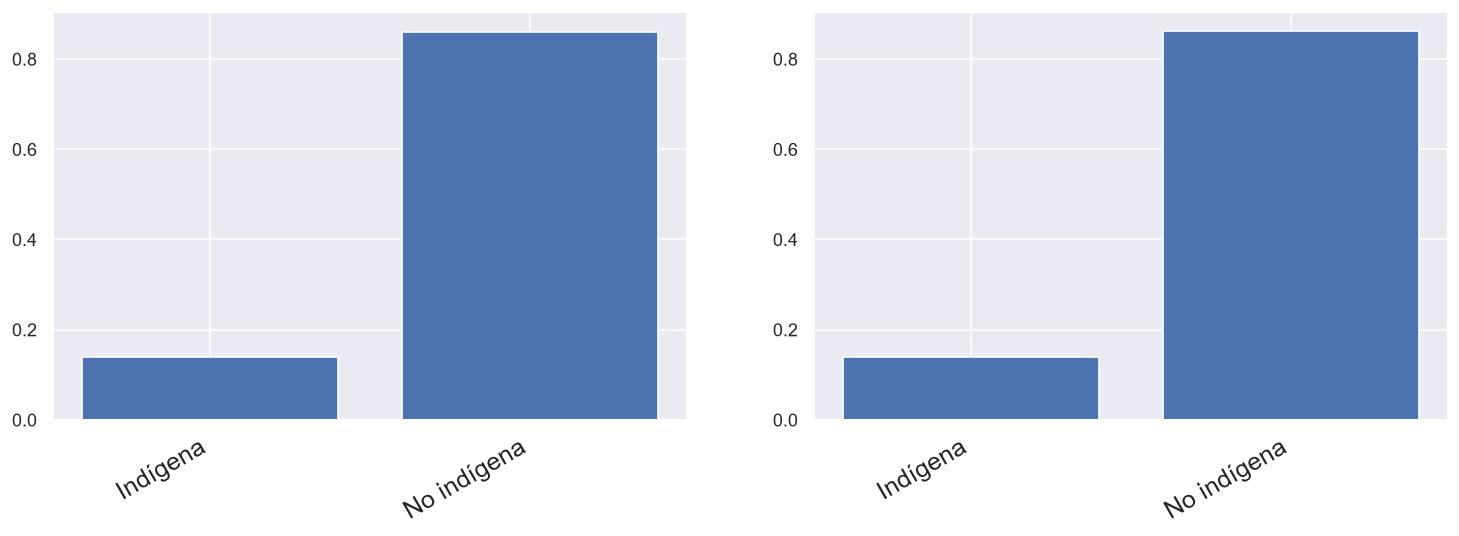

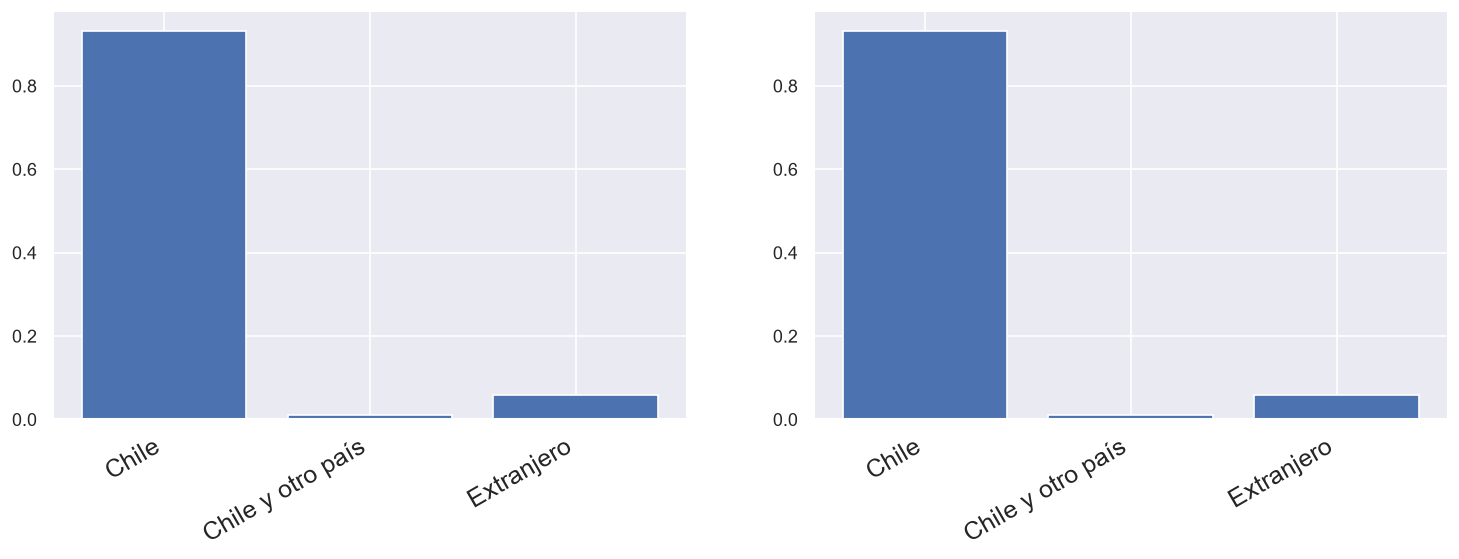

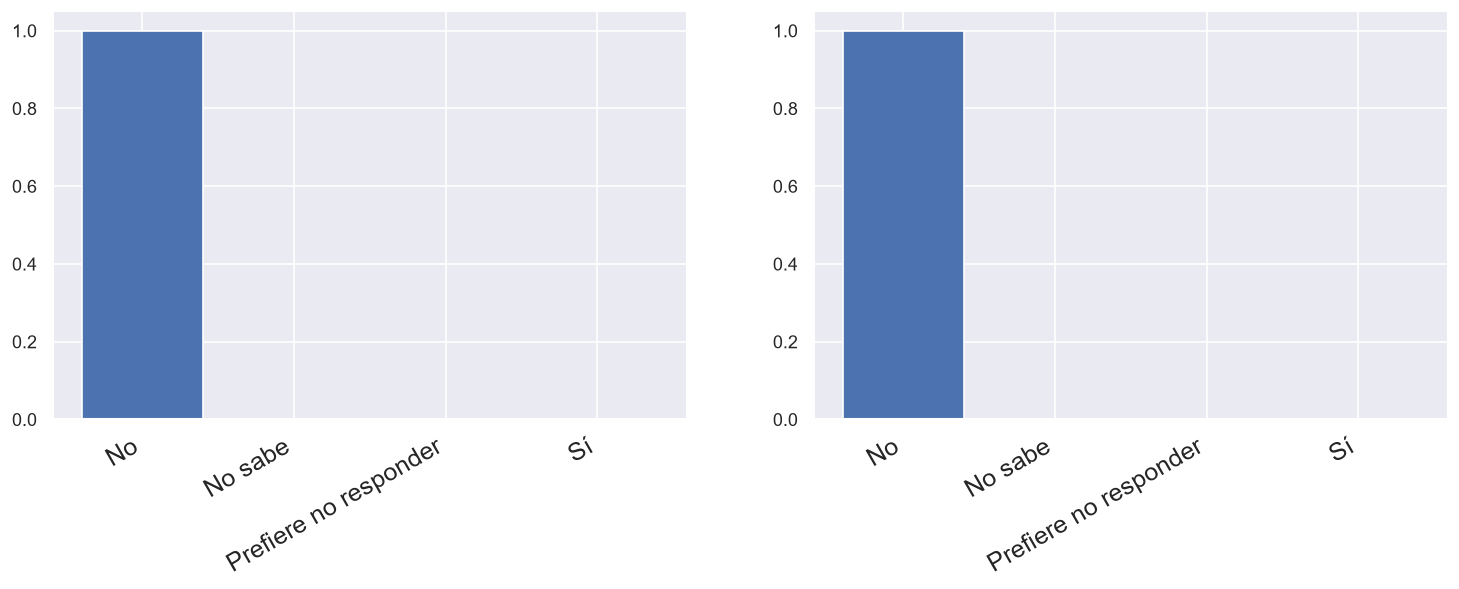

In [26]:
with open(fila_dscrp, 'r') as f:
    description_dict = json.load(f)

a_desc = description_dict.get('attribute_description', description_dict)

inspector = ModelInspector(df_7, df_syn, a_desc)

for a in cols:
    inspector.compare_histograms(a)

Imagina que ahora cuentas con este mismo dataset con información mucho más detallada, que podría contribuir a un proyecto desde la Ciencia de Datos con impacto social. Dependiendo del dataset que haya escogido su grupo, consideren el siguiente escenario:

- CIRI: el dataset incluye locaciones específicas, familias y detalles de investigación sobre desapariciones y asesinatos, lo que podría contribuir a un proyecto de búsqueda de víctimas.

- Salud: el dataset incluye identificadores de pacientes, centro de salud de atención y comuna de residencia, lo que podría contribuir a un proyecto de detección temprana o de acceso equitativo a tratamientos.

- CASEN: el dataset incluye la ubicación exacta de cada hogar, su composición familiar y el detalle de ingresos y beneficios recibidos, lo que podría contribuir a focalizar mejor la entrega de ayudas sociales.

En este caso podríamos preguntarnos, ¿qué sería lo correcto? ¿anonimizar o mantener pública toda la información?

**`Pregunta (6)` Proceso de toma de decisiones: Frente a este dilema concreto ¿incluir todos los datos por precisión y transparencia o aplicar técnicas de privacidad para proteger a las personas y sus familias? ¿cómo lo resolverías? cuales son los pros y los contras de esta decisión, en que tipo de contextos compartirías los datos reales y en cuales los datos sinteticos.**


In [27]:
# código aquí.


### `6: Activismo de datos.`

**`Pregunta (7)` Reporte los resultados de la técnica de anonimización (ModelInspector) y explique como se podría realizar activismo de datos con el conjunto anonimizado.**



In [28]:
# código aquí.